# d12_coupled_chip — nine Xmons, a direct pair and a tunable-coupler triple (legacy Quantum Metal design 12), on the Quantcore PDK

## 1 · What the chip is

**Source:** the author's legacy design notebook `components/python/12.0 Coupled_chip_layout.ipynb` (Quantum Metal
`DesignPlanar`), Quantcore internal. Spec: `docs/designs/legacy/d12_coupled_chip.md`.

A 7.5 × 7.5 mm coupled-qubit test chip: one 20/12 µm feedline across the die centre with nine λ/4 readouts (10/6 µm,
4300 … 6262 µm, shorted 36 µm from the feedline centre-line) to nine `TransmonCrossFL` Xmons, four above and five
below. Q1–Q2 is a **direct** pair (arm tips facing across a 20 µm ground strip); Q5–Q8–Q6 is a **tunable-coupler**
triple (Q8 is a flux-tunable Xmon with its own readout). Five qubits have flux lines (Q1, Q2, Q5, Q6, Q8), five a
capacitive drive pad (Q0, Q2, Q3, Q4, Q7), each wired to its own 50 Ω launchpad.

| | the rebuild keeps (source-faithful) | the Quantcore PDK changes |
|---|---|---|
| Xmons, readouts | every Metal component with the legacy options through the `metal:` wrapper (`TransmonCrossFL` with the claw, drive pad and flux-line options) at the legacy positions; the nine resonator lengths; the couplers 36 µm off the feedline (3 µm ground strip) with the shorts at the legacy `ShortToGround` positions | — |
| launchpads | `LaunchpadWirebondDriven` feed pads and the ten 50 Ω line pads with the legacy options | all twelve with their outer etch **`pad_edge` = 100 µm** from the die edge (legacy: feed pads 110 µm, line pads 155 µm) by `C.pads_to_edge`, after pinning the hangers so the couplers stay put (step 7) |
| lines | flux and drive lines through the legacy `RoutePathfinder` corner points | the first straight from each moved pad is longer (10 / 55 µm) |
| junctions | — (Metal junction footprints; the source names "smaller" / "bigger" junctions without values) | the PDK cells `Quantcore Junction` (the four fixed Xmons) / `Quantcore Squid` (the five flux-line Xmons), all at the PDK nominal 45 kΩ |
| cheese | — (12.0 has no holes) | the **PDK band** (`cheese: "auto"`) |
| placement | everything relative to the die centre | the circuit **centred in the die** where it is more than 50 µm off (step 7) |
| frame | — | the PDK die frame and device ID `D12` |

**Simplified or substituted**: KQC `Meander`s on one vertical segment instead of Metal's `RouteMeander`
arms (on the legacy meander axis where both jogs fit, else at the claw or coupler x); feedline pad leads of 20 µm
(the rest of the legacy 500 µm lead is the feedline route, so R0 and R7 couple beside it as in the source); r = 50 µm
on the flux / drive lines (legacy fillet 60 µm: the legacy corners sit 100 µm from the pins); the no-flux-line
qubits as `metal:TransmonCross` (identical geometry; the LOM gets a single JJ); the arm-to-arm couplings (no route
carries them) declared with `d.couple`, 1.67 fF each, a rough screened-CPS estimate (the `Q1_Q2` and `Q5_Q8_Q6` FEM
groups give the real value).

**Compared** (step 15) with the legacy design rebuilt headless in Quantum Metal from the legacy options
(`_legacy_b.d12_metal_reference()`): every pin position and every route's centre-line extent, next to the legacy
notebook's own screenshot.

### Changes after design review (2026-11-03)

- **#1 / #21 junctions — PDK trilayer cells, PDK rule.** The Metal junction footprints (2/0 only; the legacy external
  `JJ_grad` / `SQUID_grad` cells) are replaced by the PDK cells — `Quantcore Junction` on the four fixed Xmons,
  `Quantcore Squid` on the five flux-line Xmons (fingers 2/0 + 4/0, spacer 50/0 with the 51–53/0 gradient, CLEARER
  box), placed by the Metal wrapper on each junction line (`junction_type`). Sizing: the PDK junction rule (Nb,
  Δ = 1.4 meV, I_c·R_n = πΔ/2e = 2.20 mV, R_n 40–50 kΩ, qubits 4–8 GHz) with R_n = 45 kΩ per qubit (SQUIDs: the
  parallel pair at zero flux) → L_J 6.73 nH, C_J 15 fF (`junction_params={"lj_nH": 6.73}`). The source gives no
  junction values, so all nine get the nominal; the earlier assumed L_J = 10 nH / C_J = 2 fF are gone.

### PDK conformance pass (notebooks-legacy, 2026-11-18)

- **Pads:** `C.pads_to_edge(d)` after the routes: it first pins every hanger given by arclength `s` to its
  current coupler centre (`near=`), so the couplers do not slide when the feedline's ends move, then puts all twelve
  launchpads at `pad_edge` = 100 µm (`edge="auto"`). DRC `pad_edge` warnings: 12 → 0.
- **Centring:** `L.center_circuit` (each axis only if > 50 µm off).
- **Cheese:** the source has none: the PDK band (`"auto"`).
- **Junctions:** the PDK cells at the nominal (the legacy fix), unchanged.
- Educative layout: die → launchpads → Xmons → routes → pad rule and centring → DRC → LOM → FEM → iterate →
  export → snapshots and the Metal comparison.

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks. `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
import _legacy_b as LB                               # design-12 tables, Metal reference
from quantcore_circuits.assembly.drc import device_id_block
from quantcore_circuits.lom import estimates as est
from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "d12_coupled_chip", Path("examples/designs/legacy")

The PDK facts this rebuild uses, read from `get_pdk()` (nothing below is typed in by hand). The rules that
change a legacy chip are the **pad rule** (step 4), the **junction rule** (step 5), the **3/0 keep-out**
and the **cheese rule** (drawn by the build, step 14) and the centring of the content (step 7).

In [3]:
CHEESE_NOTE = 'PDK band (auto) — the source (12.0) has no cheese of its own'
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: PDK band (auto) — the source (12.0) has no cheese of its own |

### The source's numbers

The tables live in `_legacy_b` (`LB.D12_QUBITS`: x, y, flux line?, drive-pad side; `LB.D12_RES`: length, short x,
coupler direction and length, meander axis, row heights; `LB.D12_LINES`: the flux / drive lines' pad, qubit, pin
and the legacy `RoutePathfinder` corner points; the Metal option dicts), transcribed from the legacy notebook. Legacy
(0, 0) is the die centre: `at()` shifts by (3750, 3750) µm. The junction values are the PDK nominal.

In [4]:
X0 = Y0 = 3750                            # legacy (0, 0) → die centre
R_RES = 60                                # legacy fillet 60 µm (resonators)
R_LINE = 50                               # flux / drive lines: legacy corners 100 µm from the pins need r ≤ 50
# PDK rebuild (#1/#21): every Metal junction footprint → the PDK trilayer cell, sized by the PDK junction rule
# (Nb, Δ 1.4 meV, R_n 45 kΩ per qubit, the middle of the 40–50 kΩ; SQUIDs: the parallel total at zero flux)
JUNCTION = L.lj_for_rn(L.RN_NOMINAL_OHM)            # {"Lj_nH": 6.73, "Cj_fF": 15}: the drawn PDK junction
JJ = {"junction_type": "Quantcore Junction", "junction_params": {"lj_nH": JUNCTION["Lj_nH"]}}
SQ = {"junction_type": "Quantcore Squid", "junction_params": {"lj_nH": JUNCTION["Lj_nH"]}}
FL_X = 2700 - 20                          # feedline ends: tie of the 20 µm pad leads (legacy lead 500 µm)


def at(x, y):
    return (X0 + x, Y0 + y)


display(Markdown("| qubit | legacy (x, y) µm | flux line | drive pad |\n|---|---|---|---|\n" + "\n".join(
    f"| {n} | ({x}, {y}) | {'yes' if fl else '—'} | {dr or '—'} |" for n, (x, y, fl, dr) in LB.D12_QUBITS.items())))

| qubit | legacy (x, y) µm | flux line | drive pad |
|---|---|---|---|
| Q0 | (-1700, 2000) | — | 180 |
| Q1 | (-250, 2000) | yes | — |
| Q2 | (250, 2000) | yes | 0 |
| Q3 | (1700, 2000) | — | 0 |
| Q4 | (-1700, -2000) | — | 0 |
| Q5 | (-500, -2000) | yes | — |
| Q6 | (500, -2000) | yes | — |
| Q7 | (1700, -2000) | — | 180 |
| Q8 | (0, -2000) | yes | — |

## 3 · The die and the frame

`Designer(ID, box=...)` starts an empty 7.5 × 7.5 mm die. The PDK frame (dicing L markers 1000/0, alignment grids
1001/0, boundary 100/0, device ID `D12`) is drawn on every build; `cheese` stays `"auto"`, so the build draws the
PDK band (the source has no cheese).

(0.0, 0.0, 7500.0, 7500.0) quantcore_nb_sapphire_v1


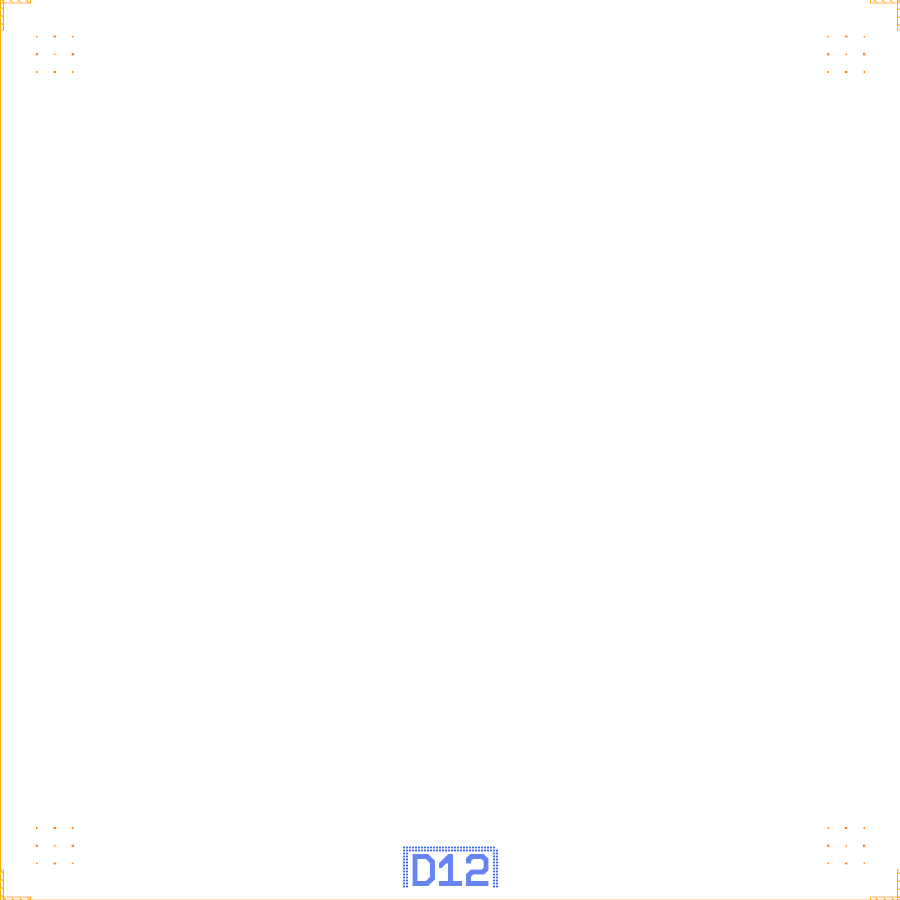

WindowsPath('build/legacy_steps/d12_coupled_chip_1_frame.png')

In [5]:
d = Designer(ID, box=(0, 0, 7500, 7500), chip={"name_chip": "D12"}, live=LIVE)   # cheese "auto"
print(d.design.chip.box, d.design.pdk)
L.step_snapshot(d, "1_frame")

## 4 · Launchpads (PDK pad rule)

Twelve Metal `LaunchpadWirebondDriven`s: the two feedline pads (`P1_C` right, `P2_C` left; 400 × 400 µm, lead 20 µm)
and the ten 50 Ω flux / drive pads (`LP_TB_*` on the bottom / top edges, `LP_LR_*` on the left / right edges), at
the legacy positions. The PDK pad rule wants each one's outer etch **`pad_edge` = 100 µm** from its die edge
(`get_pdk().frame.pad_edge`); the legacy pads sit 110 / 155 µm in. The rule is applied in step 7, after the routes:
the hangers of the readouts are given by their arclength `s` along the feedline, so they must be pinned first
(`C.pads_to_edge` does both). `L.edge_gaps` shows the legacy distances here.

pad etch → die edge (µm), legacy positions: {'P1_C': 110.0, 'P2_C': 110.0, 'LP_TB_00': 155.0, 'LP_TB_01': 155.0, 'LP_TB_02': 155.0, 'LP_TB_10': 155.0, 'LP_TB_11': 155.0, 'LP_TB_12': 155.0, 'LP_LR_00': 155.0, 'LP_LR_10': 155.0, 'LP_LR_01': 155.0, 'LP_LR_11': 155.0} | rule: 100.0


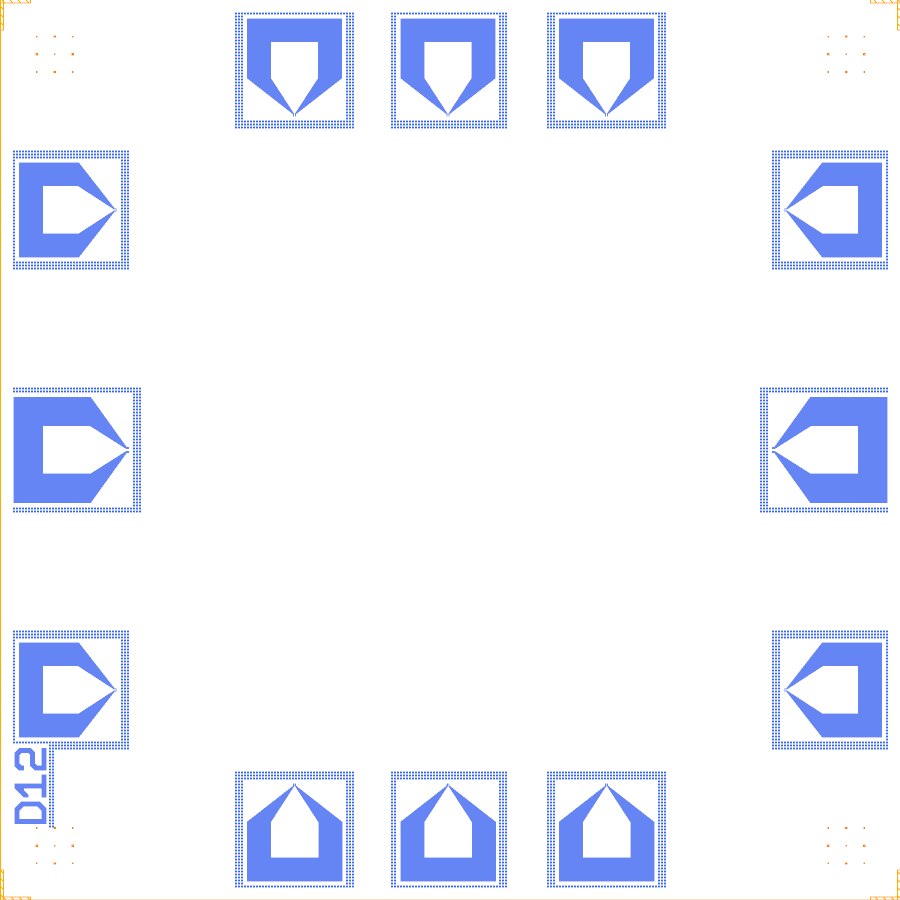

WindowsPath('build/legacy_steps/d12_coupled_chip_2_pads.png')

In [6]:
with d.batch():
    p1 = d.add("P1_C", "metal:LaunchpadWirebondDriven", at=at(2700, 0), rot=180, lead_length="20um", **LB.D12_FEED_LAUNCHPAD)
    p2 = d.add("P2_C", "metal:LaunchpadWirebondDriven", at=at(-2700, 0), rot=0, lead_length="20um", **LB.D12_FEED_LAUNCHPAD)
    pads = {n: d.add(n, "metal:LaunchpadWirebondDriven", at=at(x, y), rot=rot, **LB.D12_LINE_LAUNCHPAD)
            for n, (x, y, rot) in LB.d12_line_pads().items()}
print("pad etch → die edge (µm), legacy positions:", L.edge_gaps(d), "| rule:", get_pdk().frame.pad_edge)
L.step_snapshot(d, "2_pads")

## 5 · Components: nine Xmons and the arm couplings

`metal:TransmonCrossFL` (with flux line, the junction a SQUID) or, without the flux line, `metal:TransmonCross`
(identical geometry), each with the legacy claw (`a`) and, where the source has one, the capacitive drive pad
(`bus_drive`); rotated 180° above the feedline. Each draws the PDK trilayer cell on its junction line
(`Quantcore Junction` / `Quantcore Squid`, `junction_params={"lj_nH": 6.73}`) and carries the same values for the
LOM (`junction=`). The direct pair Q1–Q2 and the tunable-coupler triple Q5–Q8–Q6 face each other with their arm tips
across a 20 µm ground strip; no port carries that coupling, so `d.couple` declares it with a rough analytic C (screened
CPS, × 0.3), which the FEM C-matrix replaces.

C_arm = 1.67 fF; PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK).


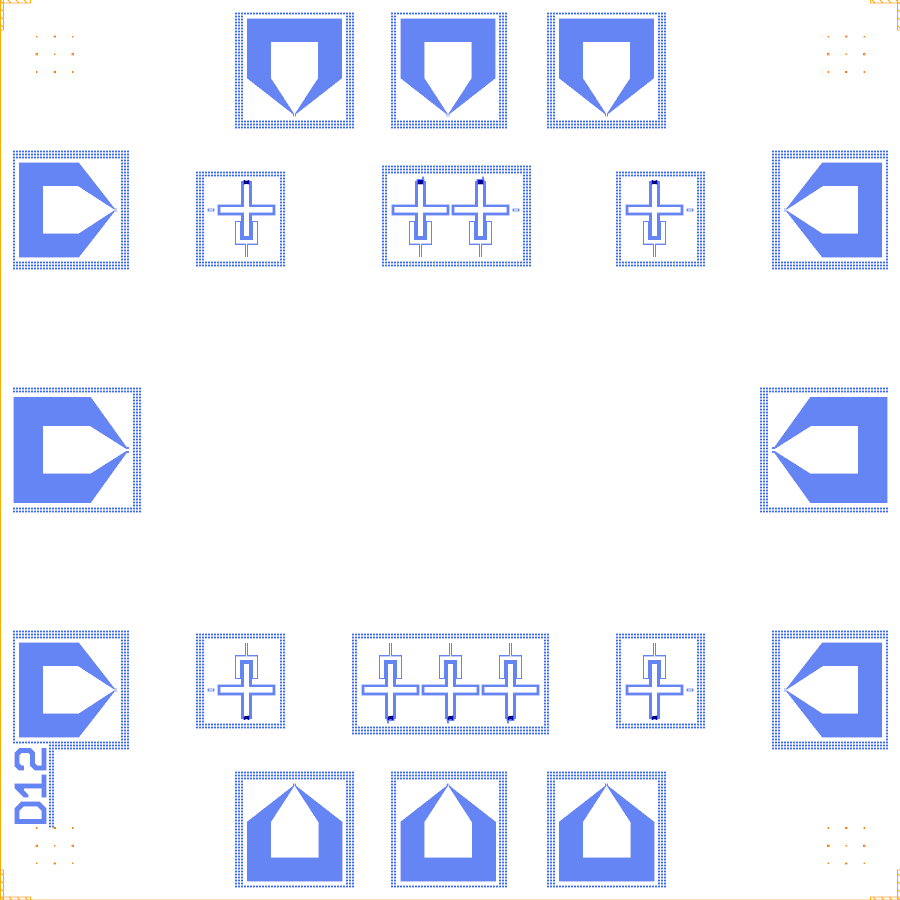

WindowsPath('build/legacy_steps/d12_coupled_chip_3_qubits.png')

In [7]:
q = {}
with d.batch():
    for n, (x, y, flux, drive) in LB.D12_QUBITS.items():
        conn = {"a": dict(LB.D12_CLAW)} | ({"bus_drive": dict(LB.D12_DRIVE_PAD, connector_location=drive)} if drive else {})
        extra = {"fl_options": dict(LB.D12_FL_OPTIONS), "gds_cell_name": "SQUID_grad"} if flux else {"gds_cell_name": "JJ_grad"}
        q[n] = d.add(n, "metal:TransmonCrossFL" if flux else "metal:TransmonCross", at=at(x, y), rot=180 if y > 0 else 0,
                     junction=JUNCTION, connection_pads=conn, **(SQ if flux else JJ), **LB.D12_CROSS, **extra)
C_ARM = round(est.coplanar_coupling(50, 220, 220, 60, est.substrate_eps(d.design.pdk), 0.3), 2)
for a, b in (("Q1", "Q2"), ("Q5", "Q8"), ("Q8", "Q6")):
    d.couple(f"C_{a}{b}", a, b, C_fF=C_ARM, note="arm tips 60 µm apart across a 20 µm ground strip (CPS × 0.3, rough)")
print(f"C_arm = {C_ARM} fF;", L.rule_md())
L.step_snapshot(d, "3_qubits")

## 6 · Routes: the feedline, nine readouts, flux and drive lines

- **Feedline** `cpw_main`: a 20/12 µm route between the two feed pads' `tie`s.
- **Readouts** `R0`–`R8`: from the claw, a jog at the legacy last-row height, down along the meander segment, a jog
  at the legacy first-row height to the far end of the coupler, then along the feedline to the short: a qcc
  **hanger** end (`fl.hanger(s=…, length=…, ground_gap=3, end="short")`, 36 µm off the feedline centre-line).
  `meander=` sets the legacy length; KQC picks the arm count.
- **Flux / drive lines** `FLX_*` / `DRV_*`: 10/6 µm from each line pad's `tie` to the qubit's `flux_line` /
  `bus_drive` pin, through the legacy corner points.

Then the sim groups (each qubit + readout: Q3D and eigenmode; the two coupled groups: Q3D).

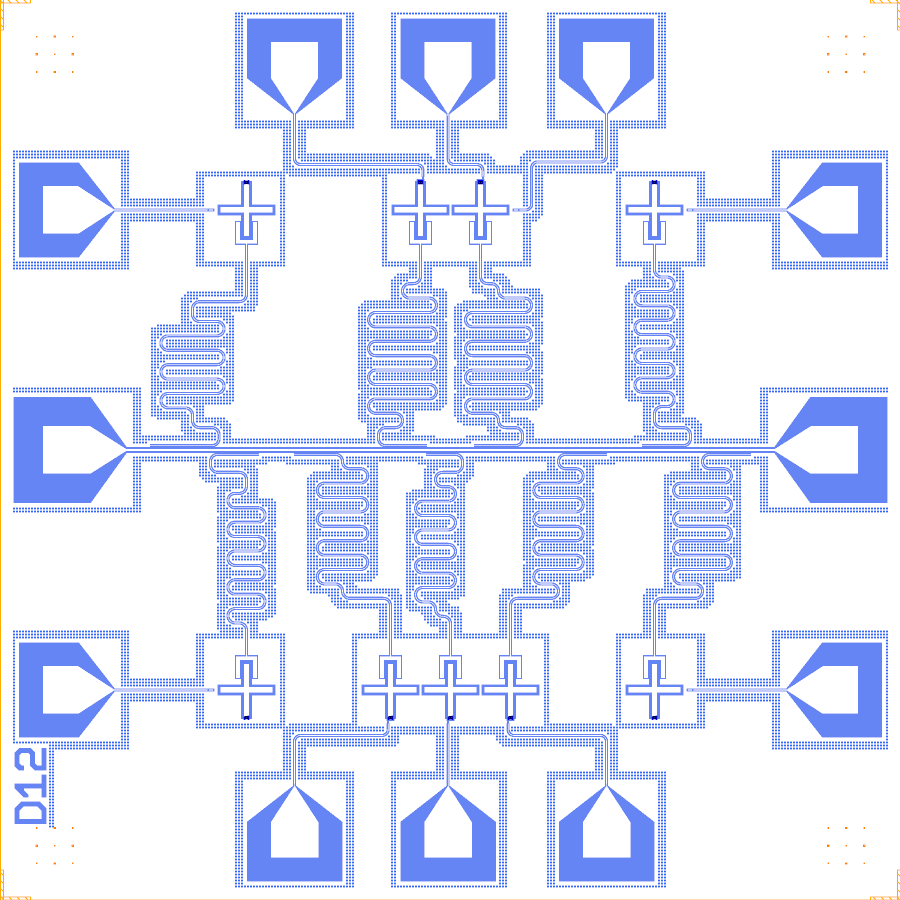

In [8]:
with d.batch():
    fl = d.route("cpw_main", p1.tie, p2.tie, a=20, b=12)            # travels −x: top side is "right"
    for n, (length, x_short, dirx, cpl, axis, y_row, y_jog) in LB.D12_RES.items():
        qn = "Q" + n[1:]
        x_q, sy = LB.D12_QUBITS[qn][0], (1 if LB.D12_QUBITS[qn][1] > 0 else -1)
        x_far, x_m = x_short + dirx * cpl, LB.d12_meander_x(n, R_RES)
        if x_m == x_q:
            nodes = [(x_q, sy * y_row), (x_far, sy * y_row)]
        elif x_m == x_far:
            nodes = [(x_q, sy * y_jog), (x_far, sy * y_jog)]
        else:
            nodes = [(x_q, sy * y_jog), (x_m, sy * y_jog), (x_m, sy * y_row), (x_far, sy * y_row)]
        hanger = fl.hanger(s=FL_X - (x_short + dirx * cpl / 2), length=cpl, side="right" if sy > 0 else "left",
                           ground_gap=3, direction="forward" if dirx > 0 else "backward", end="short")
        d.route(n, q[qn].a, hanger, meander=length, a=10, b=6, r=R_RES, nodes=[at(*p) for p in nodes])
    for pad, (qn, pin, pts) in LB.D12_LINES.items():
        d.route(f"{'FLX' if pin == 'flux_line' else 'DRV'}_{qn}", pads[pad].tie,
                q[qn][pin], a=10, b=6, r=R_LINE, nodes=[at(*p) for p in pts])
for n in LB.D12_QUBITS:
    d.sim_group(f"{n}_R{n[1:]}", [n, f"R{n[1:]}"], margin_um=300, analyses=["q3d_cmatrix", "eigenmode_epr"])
d.sim_group("Q1_Q2", ["Q1", "Q2"], margin_um=300, analyses=["q3d_cmatrix"])
d.sim_group("Q5_Q8_Q6", ["Q5", "Q8", "Q6"], margin_um=300, analyses=["q3d_cmatrix"])
L.step_snapshot(d, "4_routes")
BEFORE = {k: round(v, 1) for k, v in d.result.route_lengths().items()}

## 7 · Pad rule, cheese and centring

**Pad rule.** `C.pads_to_edge(d)` pins every hanger given by `s` to its current coupler centre (`near=`), then gives
every launchpad `edge="auto"`: each slides perpendicular to its die edge until its outer etch is 100 µm from it. The
feed pads move 10 µm out, the line pads 55 µm out; the couplers stay where they are (pinned) and the routes from the
pads get longer by the same amount.

**Cheese.** The source has none: the build draws the PDK band (`cheese: "auto"`).

**Centring.** `L.center_circuit` (each axis only if > 50 µm off); then the design is saved.

moved: ['P1_C', 'P2_C', 'LP_TB_00', 'LP_TB_01', 'LP_TB_02', 'LP_TB_10', 'LP_TB_11', 'LP_TB_12', 'LP_LR_00', 'LP_LR_10', 'LP_LR_01', 'LP_LR_11']


pad etch → die edge (µm): {'P1_C': 100.0, 'P2_C': 100.0, 'LP_TB_00': 100.0, 'LP_TB_01': 100.0, 'LP_TB_02': 100.0, 'LP_TB_10': 100.0, 'LP_TB_11': 100.0, 'LP_TB_12': 100.0, 'LP_LR_00': 100.0, 'LP_LR_10': 100.0, 'LP_LR_01': 100.0, 'LP_LR_11': 100.0}
centring shift (µm): (0.0, 0.0) | <Designer d12_coupled_chip: 21 instances, 20 routes, live=False> → examples\designs\legacy\d12_coupled_chip.json


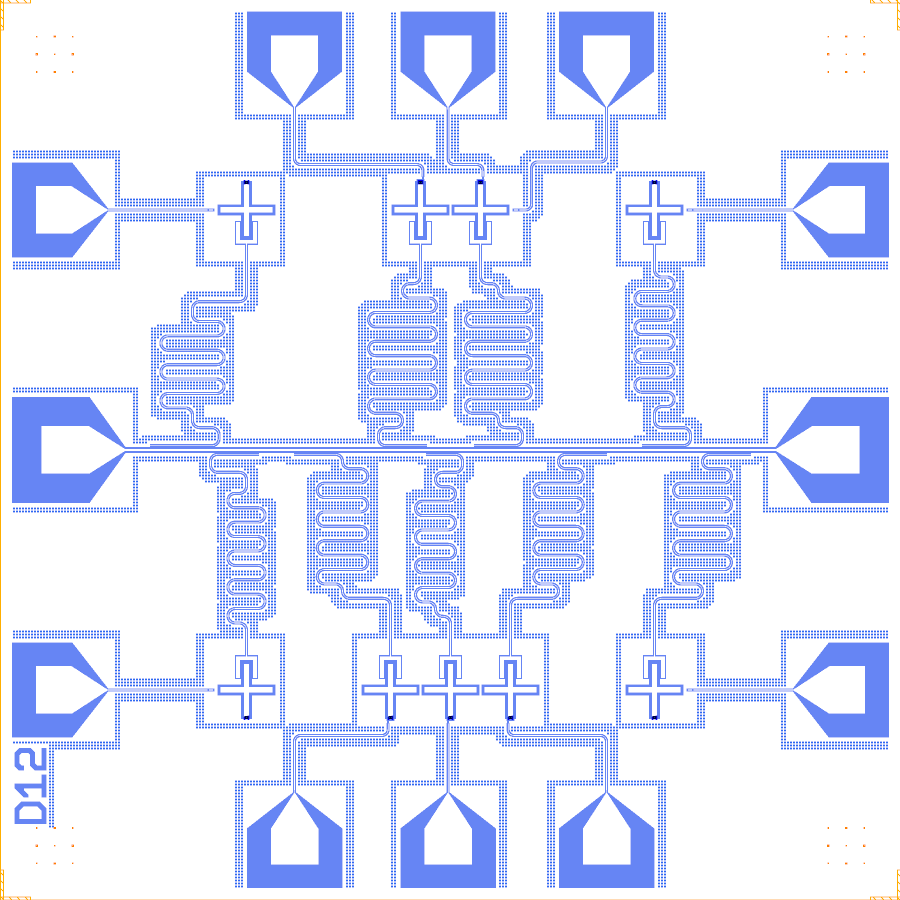

| route | before the pad rule (µm) | after (µm) | Δ |
|---|---|---|---|
| cpw_main | 5360.0 | 5380.0 | +20.0 |
| FLX_Q5 | 1238.1 | 1293.1 | +55.0 |
| DRV_Q2 | 1439.6 | 1494.6 | +55.0 |
| FLX_Q8 | 501.0 | 556.0 | +55.0 |
| FLX_Q6 | 1278.1 | 1333.1 | +55.0 |
| FLX_Q1 | 1528.1 | 1583.1 | +55.0 |
| FLX_Q2 | 748.1 | 803.1 | +55.0 |
| DRV_Q0 | 754.0 | 809.0 | +55.0 |
| DRV_Q4 | 754.0 | 809.0 | +55.0 |
| DRV_Q7 | 754.0 | 809.0 | +55.0 |
| DRV_Q3 | 754.0 | 809.0 | +55.0 |

device ID block (µm): (100,600;400,1300)


In [9]:
moved = C.pads_to_edge(d)                                    # pins the hangers first (near=), then edge="auto"
SHIFT = L.center_circuit(d)
DESIGN = d.save(OUT / f"{ID}.json")
print("moved:", moved)
print("pad etch → die edge (µm):", L.edge_gaps(d))
print("centring shift (µm):", SHIFT, "|", d, "→", DESIGN)
L.step_snapshot(d, "5_pads_rule")
AFTER = {k: round(v, 1) for k, v in d.result.route_lengths().items()}
display(Markdown("| route | before the pad rule (µm) | after (µm) | Δ |\n|---|---|---|---|\n" + "\n".join(
    f"| {k} | {BEFORE[k]} | {AFTER[k]} | {AFTER[k] - BEFORE[k]:+.1f} |" for k in AFTER if abs(AFTER[k] - BEFORE[k]) > 0.05)))
print("device ID block (µm):", device_id_block(d.result))

## 8 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip, a route looping over itself or running over a component) must be fixed; **warnings** are
reported for a person to judge (a dangling open end, two cells' bounding boxes touching); **PDK design warnings**
(`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside the PDK margins — they are never retuned for, only
listed. `C.pdk_report(d)` summarises the PDK checks: cheese source, content centring (free text labels left out),
junction types and the design warnings.

Expected (this run): zero errors; 30 `dangling_port` warnings, all by design: every launchpad's `in` (12: the bond pad
itself, bonded, never routed) and each Xmon's `squid_a` / `squid_b` (18: junction attachment points of the Metal
wrapper, not route ends). No PDK design warnings: the twelve launchpads at 100 µm (no `pad_edge`), the nine
junctions at the nominal 45 kΩ. Every edge centre holds a launchpad, so the device ID `D12` sits on the left edge,
(100, 600)–(400, 1300) µm, clear of `LP_LR_00`. `pdk_report`: cheese "PDK band", content centre (+0, +0) µm,
junction types `Quantcore Junction` × 4, `Quantcore Squid` × 5.

In [10]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

warning dangling_port LP_LR_00.in is not connected (no route or snap)
warning dangling_port LP_LR_01.in is not connected (no route or snap)
warning dangling_port LP_LR_10.in is not connected (no route or snap)
warning dangling_port LP_LR_11.in is not connected (no route or snap)
warning dangling_port LP_TB_00.in is not connected (no route or snap)
warning dangling_port LP_TB_01.in is not connected (no route or snap)
warning dangling_port LP_TB_02.in is not connected (no route or snap)
warning dangling_port LP_TB_10.in is not connected (no route or snap)
warning dangling_port LP_TB_11.in is not connected (no route or snap)
warning dangling_port LP_TB_12.in is not connected (no route or snap)
warning dangling_port P1_C.in is not connected (no route or snap)
warning dangling_port P2_C.in is not connected (no route or snap)
warning dangling_port Q0.squid_a is not connected (no route or snap)
warning dangling_port Q0.squid_b is not connected (no route or snap)
warning dangling_port Q1.squid

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 4, Quantcore Squid × 5 |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

The feedline is one node (both feed pads, 50 Ω each end) with nine HANGER κ elements. Each qubit: island (C and JJ
or SQUID to ground) — C_g — claw node — λ/4 readout to ground. A drive line joins its pad's 50 Ω port to the qubit's
`bus_drive` node (C_g across the 30 µm gap connector); a flux line ends on `control:flux` (Q1, Q2, Q5, Q6, Q8). The
three declared couplings join the facing islands. The "unconnected ports" are the launchpads' `in` (the bond pads),
each on its pad node.

In [11]:
lb = d.lom()
C.show_netlist(lb)
print(C.lom_summary(lb))

**25 nodes · 74 branches · 5 controls · 12 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `cpw_main` | `cpw_main`, `P1_C.pad`, `P2_C.pad` |
| `Q2.bus_drive` | `LP_TB_12.pad`, `Q2.bus_drive` |
| `Q4.bus_drive` | `LP_LR_00.pad`, `Q4.bus_drive` |
| `Q0.bus_drive` | `LP_LR_10.pad`, `Q0.bus_drive` |
| `Q7.bus_drive` | `LP_LR_01.pad`, `Q7.bus_drive` |
| `Q3.bus_drive` | `LP_LR_11.pad`, `Q3.bus_drive` |
| `Q0` | `Q0.island` |
| `Q0.a` | `Q0.a` |
| `Q1` | `Q1.island` |
| `Q1.a` | `Q1.a` |
| `Q2` | `Q2.island` |
| `Q2.a` | `Q2.a` |
| `Q3` | `Q3.island` |
| `Q3.a` | `Q3.a` |
| `Q4` | `Q4.island` |
| `Q4.a` | `Q4.a` |
| `Q5` | `Q5.island` |
| `Q5.a` | `Q5.a` |
| `Q6` | `Q6.island` |
| `Q6.a` | `Q6.a` |
| `Q7` | `Q7.island` |
| `Q7.a` | `Q7.a` |
| `Q8` | `Q8.island` |
| `Q8.a` | `Q8.a` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_P1_C` | R | `cpw_main` – `gnd` | 50 Ω |
| `Port_P2_C` | R | `cpw_main` – `gnd` | 50 Ω |
| `Port_LP_TB_12` | R | `Q2.bus_drive` – `gnd` | 50 Ω |
| `Port_LP_LR_00` | R | `Q4.bus_drive` – `gnd` | 50 Ω |
| `Port_LP_LR_10` | R | `Q0.bus_drive` – `gnd` | 50 Ω |
| `Port_LP_LR_01` | R | `Q7.bus_drive` – `gnd` | 50 Ω |
| `Port_LP_LR_11` | R | `Q3.bus_drive` – `gnd` | 50 Ω |
| `C_Q0` | C | `Q0` – `gnd` | 120 fF |
| `J_Q0` | JJ | `Q0` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q0_a` | C | `Q0` – `Q0.a` | 5.2 fF |
| `Cc_Q0_a` | C | `Q0.a` – `gnd` | 121 fF |
| `Cg_Q0_bus_drive` | C | `Q0` – `Q0.bus_drive` | 0.09 fF |
| `Cc_Q0_bus_drive` | C | `Q0.bus_drive` – `gnd` | 11.8 fF |
| `C_Q1` | C | `Q1` – `gnd` | 120 fF |
| `J_Q1` | SQUID | `Q1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_a` | C | `Q1` – `Q1.a` | 5.2 fF |
| `Cc_Q1_a` | C | `Q1.a` – `gnd` | 121 fF |
| `C_Q2` | C | `Q2` – `gnd` | 120 fF |
| `J_Q2` | SQUID | `Q2` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_a` | C | `Q2` – `Q2.a` | 5.2 fF |
| `Cc_Q2_a` | C | `Q2.a` – `gnd` | 121 fF |
| `Cg_Q2_bus_drive` | C | `Q2` – `Q2.bus_drive` | 0.09 fF |
| `Cc_Q2_bus_drive` | C | `Q2.bus_drive` – `gnd` | 11.8 fF |
| `C_Q3` | C | `Q3` – `gnd` | 120 fF |
| `J_Q3` | JJ | `Q3` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q3_a` | C | `Q3` – `Q3.a` | 5.2 fF |
| `Cc_Q3_a` | C | `Q3.a` – `gnd` | 121 fF |
| `Cg_Q3_bus_drive` | C | `Q3` – `Q3.bus_drive` | 0.09 fF |
| `Cc_Q3_bus_drive` | C | `Q3.bus_drive` – `gnd` | 11.8 fF |
| `C_Q4` | C | `Q4` – `gnd` | 120 fF |
| `J_Q4` | JJ | `Q4` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q4_a` | C | `Q4` – `Q4.a` | 5.2 fF |
| `Cc_Q4_a` | C | `Q4.a` – `gnd` | 121 fF |
| `Cg_Q4_bus_drive` | C | `Q4` – `Q4.bus_drive` | 0.09 fF |
| `Cc_Q4_bus_drive` | C | `Q4.bus_drive` – `gnd` | 11.8 fF |
| `C_Q5` | C | `Q5` – `gnd` | 120 fF |
| `J_Q5` | SQUID | `Q5` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q5_a` | C | `Q5` – `Q5.a` | 5.2 fF |
| `Cc_Q5_a` | C | `Q5.a` – `gnd` | 121 fF |
| `C_Q6` | C | `Q6` – `gnd` | 120 fF |
| `J_Q6` | SQUID | `Q6` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q6_a` | C | `Q6` – `Q6.a` | 5.2 fF |
| `Cc_Q6_a` | C | `Q6.a` – `gnd` | 121 fF |
| `C_Q7` | C | `Q7` – `gnd` | 120 fF |
| `J_Q7` | JJ | `Q7` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q7_a` | C | `Q7` – `Q7.a` | 5.2 fF |
| `Cc_Q7_a` | C | `Q7.a` – `gnd` | 121 fF |
| `Cg_Q7_bus_drive` | C | `Q7` – `Q7.bus_drive` | 0.09 fF |
| `Cc_Q7_bus_drive` | C | `Q7.bus_drive` – `gnd` | 11.8 fF |
| `C_Q8` | C | `Q8` – `gnd` | 120 fF |
| `J_Q8` | SQUID | `Q8` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q8_a` | C | `Q8` – `Q8.a` | 5.2 fF |
| `Cc_Q8_a` | C | `Q8.a` – `gnd` | 121 fF |
| `C_C_Q1Q2` | C | `Q1` – `Q2` | 1.67 fF |
| `C_C_Q5Q8` | C | `Q5` – `Q8` | 1.67 fF |
| `C_C_Q8Q6` | C | `Q8` – `Q6` | 1.67 fF |
| `R0` | TLres | `Q0.a` – `gnd` | lambda/4, 5493 µm, 5.736 GHz |
| `K_R0` | HANGER | `Q0.a` – `cpw_main` | κ 0.775 MHz (L 572 µm) |
| `R1` | TLres | `Q1.a` – `gnd` | lambda/4, 6262 µm, 5.032 GHz |
| `K_R1` | HANGER | `Q1.a` – `cpw_main` | κ 0.257 MHz (L 400 µm) |
| `R2` | TLres | `Q2.a` – `gnd` | lambda/4, 6140 µm, 5.132 GHz |
| `K_R2` | HANGER | `Q2.a` – `cpw_main` | κ 0.273 MHz (L 400 µm) |
| `R3` | TLres | `Q3.a` – `gnd` | lambda/4, 4638 µm, 6.794 GHz |
| `K_R3` | HANGER | `Q3.a` – `cpw_main` | κ 0.632 MHz (L 400 µm) |
| `R4` | TLres | `Q4.a` – `gnd` | lambda/4, 4475 µm, 7.041 GHz |
| `K_R4` | HANGER | `Q4.a` – `cpw_main` | κ 0.703 MHz (L 400 µm) |
| `R5` | TLres | `Q5.a` – `gnd` | lambda/4, 5200 µm, 6.059 GHz |
| `K_R5` | HANGER | `Q5.a` – `cpw_main` | κ 0.449 MHz (L 400 µm) |
| `R6` | TLres | `Q6.a` – `gnd` | lambda/4, 5132 µm, 6.140 GHz |
| `K_R6` | HANGER | `Q6.a` – `cpw_main` | κ 0.467 MHz (L 400 µm) |
| `R7` | TLres | `Q7.a` – `gnd` | lambda/4, 5690 µm, 5.538 GHz |
| `K_R7` | HANGER | `Q7.a` – `cpw_main` | κ 0.343 MHz (L 400 µm) |
| `R8` | TLres | `Q8.a` – `gnd` | lambda/4, 4300 µm, 7.328 GHz |
| `K_R8` | HANGER | `Q8.a` – `cpw_main` | κ 0.447 MHz (L 300 µm) |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `FLX_Q5` | flux_bias | `J_Q5` | `FLX_Q5` | 1293 |
| `FLX_Q8` | flux_bias | `J_Q8` | `FLX_Q8` | 556 |
| `FLX_Q6` | flux_bias | `J_Q6` | `FLX_Q6` | 1333 |
| `FLX_Q1` | flux_bias | `J_Q1` | `FLX_Q1` | 1583 |
| `FLX_Q2` | flux_bias | `J_Q2` | `FLX_Q2` | 803 |

**Unconnected ports:** `LP_LR_00.in`, `LP_LR_01.in`, `LP_LR_10.in`, `LP_LR_11.in`, `LP_TB_00.in`, `LP_TB_01.in`, `LP_TB_02.in`, `LP_TB_10.in`, `LP_TB_11.in`, `LP_TB_12.in`, `P1_C.in`, `P2_C.in`

**Builder notes:**

- Port_LP_TB_00: both ends on gnd after merging conductors (dropped)
- Port_LP_TB_01: both ends on gnd after merging conductors (dropped)
- Port_LP_TB_02: both ends on gnd after merging conductors (dropped)
- Port_LP_TB_10: both ends on gnd after merging conductors (dropped)
- Port_LP_TB_11: both ends on gnd after merging conductors (dropped)

{'nodes': 24, 'branches': 74, 'controls': 5, 'unconnected': 12}


## 10 · LOM simulation

Every qubit with its readout (the feedline as a 25 Ω load): QuCat normal modes and κ, then the QuTiP-dressed f_q, α,
f_r and χ. Then the two coupled groups, qubits only: with the same L_J on every qubit they are on resonance, so the
normal-mode splitting gives the coupling directly (for two identical qubits, 2g).

In [12]:
pairs = {f"{q}+R{q[1:]}": [q, f"R{q[1:]}"] for q in LB.D12_QUBITS}
results = C.simulate_groups(d, pairs)
display(Markdown(C.groups_md(results)))
coupled = C.simulate_groups(d, {"Q1–Q2 (direct)": ["Q1", "Q2"], "Q5–Q8–Q6 (tunable coupler)": ["Q5", "Q8", "Q6"]})
for g, res in coupled.items():
    f = sorted(m.f_GHz for m in res.modes)
    display(Markdown(f"**{g}** — normal modes (QuCat); splitting {1000 * (f[-1] - f[0]):.1f} MHz\n\n" + C.modes_md(res)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q0+R0 | Q0 | 5.0591 | -196.9 | R0 | 4.9357 | 0.411 | 64.7 |
| Q1+R1 | Q1 | 5.0411 | -146 | R1 | 4.4242 | 0.153 | -1.64 |
| Q2+R2 | Q2 | 5.0401 | -145.2 | R2 | 4.5015 | 0.161 | -2.37 |
| Q3+R3 | Q3 | 5.0325 | -146 | R3 | 5.7585 | 0.323 | -1.59 |
| Q4+R4 | Q4 | 5.0331 | -146.4 | R4 | 5.937 | 0.354 | -1.16 |
| Q5+R5 | Q5 | 5.0248 | -135.7 | R5 | 5.226 | 0.165 | -11 |
| Q6+R6 | Q6 | 5.0277 | -139.6 | R6 | 5.283 | 0.216 | -7.82 |
| Q7+R7 | Q7 | 5.046 | -124.6 | R7 | 4.8085 | 0.192 | -22.7 |
| Q8+R8 | Q8 | 5.0352 | -146.8 | R8 | 6.1513 | 0.221 | -0.86 |

**Q1–Q2 (direct)** — normal modes (QuCat); splitting 60.7 MHz

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q2 | qubit | 5.1220 | 0 | 67.6 | J_Q2 0.51, J_Q1 0.49 |
| Q1 | qubit | 5.1828 | 0 | 69.2 | J_Q1 0.51, J_Q2 0.49 |

**Q5–Q8–Q6 (tunable coupler)** — normal modes (QuCat); splitting 90.3 MHz

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q8 | qubit | 5.0932 | 0 | 66.8 | J_Q8 0.67, J_Q5 0.17, J_Q6 0.17 |
| Q5 | qubit | 5.1529 | 0 | 68.4 | J_Q5 0.50, J_Q6 0.50 |
| Q6 | qubit | 5.1836 | 0 | 46.1 | J_Q5 0.33, J_Q8 0.33, J_Q6 0.33 |

**Reading the numbers** (LOM of this run; R_n 45 kΩ, L_J 6.73 nH on every qubit, the SQUIDs at zero flux). Every Xmon sits at
5.02–5.06 GHz. The claw loads each readout (the legacy lengths were simulated without the claws, #12): R1 4.42, R2
4.50, R7 4.81, R0 4.94, R5 5.23, R6 5.28, R3 5.76, R4 5.94, R8 6.15 GHz. **Q0/R0 (5.06 / 4.94 GHz, χ 65 MHz)
hybridise**; Q7/R7 (χ −23 MHz), Q5/R5 (−11 MHz) and Q6/R6 (−7.8 MHz) are close; R1 / R2 sit ≈ 0.55 GHz *below*
their qubits. The coupled groups split by 61 MHz (Q1–Q2) and 90 MHz (Q5–Q8–Q6) with the rough 1.67 fF arm estimate
(the FEM groups `Q1_Q2`, `Q5_Q8_Q6` give the real value); Q8 is flux-tunable, so in operation it is detuned from
Q5 / Q6. Detuning Q0 and Q7 is a design decision (step 13 shows one way).

## 11 · FEM: send the job

Each sim group is cut out of the chip (its instances plus a margin of ground), with the PDK stack (sapphire
650 µm, ε_r 10.25) and **without cheese** (simulation exports never have it), and written as a job folder
under `build/jobs/` (`C.export_sims` → `build_simulation` + `export_job`): a Q3D C-matrix job by default,
`analysis="eigenmode_epr"` for the eigenmode / EPR job. With `RUN_FEM = True` and AEDT 2024 R1 (v241) or
newer on this machine, `L.fem_send` solves each job in a **new batch, non-graphical** AEDT
(`sim_tools.hfss.solve_job`) — it never touches an AEDT window you have open. The default here is
`False`: export only.

Here: one Q3D C-matrix and one eigenmode / EPR job per qubit / readout group, and one Q3D job per coupled group (the
C-matrix gives the arm-to-arm couplings that `d.couple` only estimates).

In [13]:
RUN_FEM = False                       # True: solve the exported jobs here (AEDT 2024 R1+, batch)
jobs = C.export_sims(DESIGN)
display(Markdown(C.jobs_md(jobs)))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q0_R0 | `build/jobs/d12_coupled_chip_Q0_R0_q3d_cmatrix` | 1 · junction · `Q0.junction`<br>2 · waveguide · `Q0.a`<br>3 · edge · `DRV_Q0`<br>4 · edge · `FLX_Q1` | `Q0.island`, `Q0.a`, `FLX_Q1`, `Q0.bus_drive` |
| Q1_R1 | `build/jobs/d12_coupled_chip_Q1_R1_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `Q1.a`<br>3 · edge · `FLX_Q1`<br>4 · edge · `FLX_Q2` | `Q1.island`, `Q1.a` |
| Q2_R2 | `build/jobs/d12_coupled_chip_Q2_R2_q3d_cmatrix` | 1 · junction · `Q2.junction`<br>2 · waveguide · `Q2.a`<br>3 · edge · `DRV_Q2`<br>4 · edge · `FLX_Q1`<br>5 · edge · `FLX_Q2` | `Q2.island`, `Q2.a`, `Q2.bus_drive` |
| Q3_R3 | `build/jobs/d12_coupled_chip_Q3_R3_q3d_cmatrix` | 1 · junction · `Q3.junction`<br>2 · waveguide · `Q3.a`<br>3 · edge · `DRV_Q2`<br>4 · edge · `DRV_Q3` | `Q3.island`, `Q3.a`, `DRV_Q2`, `Q3.bus_drive` |
| Q4_R4 | `build/jobs/d12_coupled_chip_Q4_R4_q3d_cmatrix` | 1 · junction · `Q4.junction`<br>2 · waveguide · `Q4.a`<br>3 · edge · `DRV_Q4`<br>4 · edge · `FLX_Q5` | `Q4.island`, `Q4.a`, `FLX_Q5`, `Q4.bus_drive` |
| Q5_R5 | `build/jobs/d12_coupled_chip_Q5_R5_q3d_cmatrix` | 1 · junction · `Q5.junction`<br>2 · waveguide · `Q5.a`<br>3 · edge · `FLX_Q5`<br>4 · edge · `FLX_Q8` | `Q5.island`, `Q5.a` |
| Q6_R6 | `build/jobs/d12_coupled_chip_Q6_R6_q3d_cmatrix` | 1 · junction · `Q6.junction`<br>2 · waveguide · `Q6.a`<br>3 · edge · `FLX_Q6`<br>4 · edge · `FLX_Q8` | `Q6.island`, `Q6.a` |
| Q7_R7 | `build/jobs/d12_coupled_chip_Q7_R7_q3d_cmatrix` | 1 · junction · `Q7.junction`<br>2 · waveguide · `Q7.a`<br>3 · edge · `DRV_Q7`<br>4 · edge · `FLX_Q6` | `Q7.island`, `Q7.a`, `FLX_Q6`, `Q7.bus_drive` |
| Q8_R8 | `build/jobs/d12_coupled_chip_Q8_R8_q3d_cmatrix` | 1 · junction · `Q8.junction`<br>2 · waveguide · `Q8.a`<br>3 · edge · `FLX_Q5`<br>4 · edge · `FLX_Q6`<br>5 · edge · `FLX_Q8` | `Q8.island`, `Q8.a` |
| Q1_Q2 | `build/jobs/d12_coupled_chip_Q1_Q2_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · junction · `Q2.junction`<br>3 · edge · `DRV_Q2`<br>4 · edge · `FLX_Q1`<br>5 · edge · `FLX_Q2` | `Q1.island`, `Q2.island`, `Q2.bus_drive` |
| Q5_Q8_Q6 | `build/jobs/d12_coupled_chip_Q5_Q8_Q6_q3d_cmatrix` | 1 · junction · `Q5.junction`<br>2 · junction · `Q8.junction`<br>3 · junction · `Q6.junction`<br>4 · edge · `FLX_Q5`<br>5 · edge · `FLX_Q6`<br>6 · edge · `FLX_Q8` | `Q5.island`, `Q8.island`, `Q6.island` |

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

`RUN_FEM = False`: 11 job(s) exported, none solved. Set `RUN_FEM = True` to solve them here (batch, non-graphical), or run `qcc sim run <job>` on a machine with AEDT 2024 R1+.

## 12 · Bring the results back

A solved job leaves `results/results.json` in its folder. `fill(model, DESIGN, job)` then replaces the LOM's
component estimates by the FEM C-matrix, matched by net name (the net names are the ones in the job table
above), and the LOM is simulated again with them. `L.fem_bring_back` does this for every job that has
results and says which have none yet.

No job has been solved yet, so the cell says so. With results, the coupled groups' C-matrix would replace the 1.67 fF
arm estimate, and the qubit groups' the claw and island capacitances.

In [14]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM results yet for 11 job(s) (`build/jobs/d12_coupled_chip_Q0_R0_q3d_cmatrix`, `build/jobs/d12_coupled_chip_Q1_R1_q3d_cmatrix`, `build/jobs/d12_coupled_chip_Q2_R2_q3d_cmatrix`, `build/jobs/d12_coupled_chip_Q3_R3_q3d_cmatrix`, …). After a solve each job holds `results/results.json`; this cell then fills the LOM with the extracted C-matrix (`fill(model, DESIGN, job)`) and shows the estimate next to the FEM value per capacitance, and f_q / α / f_r / χ re-simulated with them.

## 13 · Iterate: change one property and re-simulate

Q0 sits on its loaded readout R0 (step 10: hybridised). A copy moves Q0's junction to the low end of the PDK window,
**R_n 40 kΩ** (`L.lj_for_rn(40e3)`: the L_J and C_J of a PDK-drawn junction of that R_n, and the drawn cell's
`lj_nH`): L_J falls by 11 %, f_q rises by ≈ 6 %, away from R0. The copy is not saved; detuning Q0 is a design decision.

In [15]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved design
J40 = L.lj_for_rn(40e3)
d2["Q0"].set(junction=J40, junction_params={"lj_nH": J40["Lj_nH"]})
after = C.simulate_groups(d2, {"Q0+R0": pairs["Q0+R0"]})["Q0+R0"]
print("Q0 junction:", JUNCTION, "→", J40)
display(Markdown(L.compare_md(results["Q0+R0"], after, keys=["Q0.f_q_GHz", "Q0.alpha_MHz", "R0.f_GHz", "R0.chi_MHz"],
                              label=("R_n 45 kΩ", "R_n 40 kΩ"))))

Q0 junction: {'Lj_nH': 6.7344, 'Cj_fF': 15.0} → {'Lj_nH': 5.9862, 'Cj_fF': 16.875}


| parameter | R_n 45 kΩ | R_n 40 kΩ | Δ |
|---|---|---|---|
| `Q0.f_q_GHz` | 5.0591 | 5.323 | +0.2638 |
| `Q0.alpha_MHz` | -196.94 | -137.53 | +59.41 |
| `R0.f_GHz` | 4.9357 | 4.9518 | +0.01604 |
| `R0.chi_MHz` | 64.737 | -7.3742 | -72.11 |

## 14 · Build and export

The design is saved as JSON (`DESIGN`, step 7): it is the source of truth — the layout, the netlist, the
FEM jobs and the mask are all made from it. The **fab mask** (`export_fab`) keeps only the PDK fab layers
(1/0 etch, 2/0 + 4/0 junction fingers, 3/0 second-metal keep-out, 50–53/0 spacer, 100/0 boundary, 1000/0 +
1001/0 markers), rounds the corners (radius ∝ each polygon's shortest dimension) and keeps the build's
cheese; every cheese hole of 1/0 is also on 3/0. **Simulation exports** never carry cheese; they drop airbridges
unless asked (`build_simulation(..., airbridges=True)`); the legacy chips have none.

Here: `cheese=True` (the default): the build already carries the PDK band (12.0 has no cheese), so the mask keeps
it (`cheese_source` "build").

The same from a shell:

```
qcc build examples/designs/legacy/d12_coupled_chip.json                    # layout → build/d12_coupled_chip.oas
qcc mask  examples/designs/legacy/d12_coupled_chip.json          # fab mask with the PDK rules
qcc sim build examples/designs/legacy/d12_coupled_chip.json -g Q0_R0 -a q3d_cmatrix   # one FEM job (step 11)
qcc sim run build/jobs/d12_coupled_chip_Q0_R0_q3d_cmatrix              # solve it (AEDT 2024 R1+)
```

In [16]:
display(Markdown(L.fab_md(d)))

Fab mask: `build/d12_coupled_chip_fab.oas` · cheese source **build** (14723 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 14765 |
| 2/0 | JJ_STRAIGHT | 9 |
| 3/0 | M3 | 14727 |
| 4/0 | JJ_BENT | 9 |
| 50/0 | HSQ | 28 |
| 51/0 | SPACER_1 | 28 |
| 52/0 | SPACER_2 | 28 |
| 53/0 | SPACER_3 | 28 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

## 15 · Snapshots and comparison with the legacy geometry

The full chip, the legacy notebook's own Metal screenshot (`docs/images/designs/legacy/d12_coupled_chip_legacy.png`),
zooms on the direct pair, Q8's SQUID and R8's short, then the comparison with the legacy design rebuilt headless in
Quantum Metal (`LB.d12_metal_reference()`, ≈ 5 s): every pin position (the twelve launchpads' pins moved by the pad
rule: 10 µm for the feed pads, 55 µm for the line pads), and every readout's centre-line extent (the rebuilt gap
outline shrunk by a/2 + b = 11 µm).

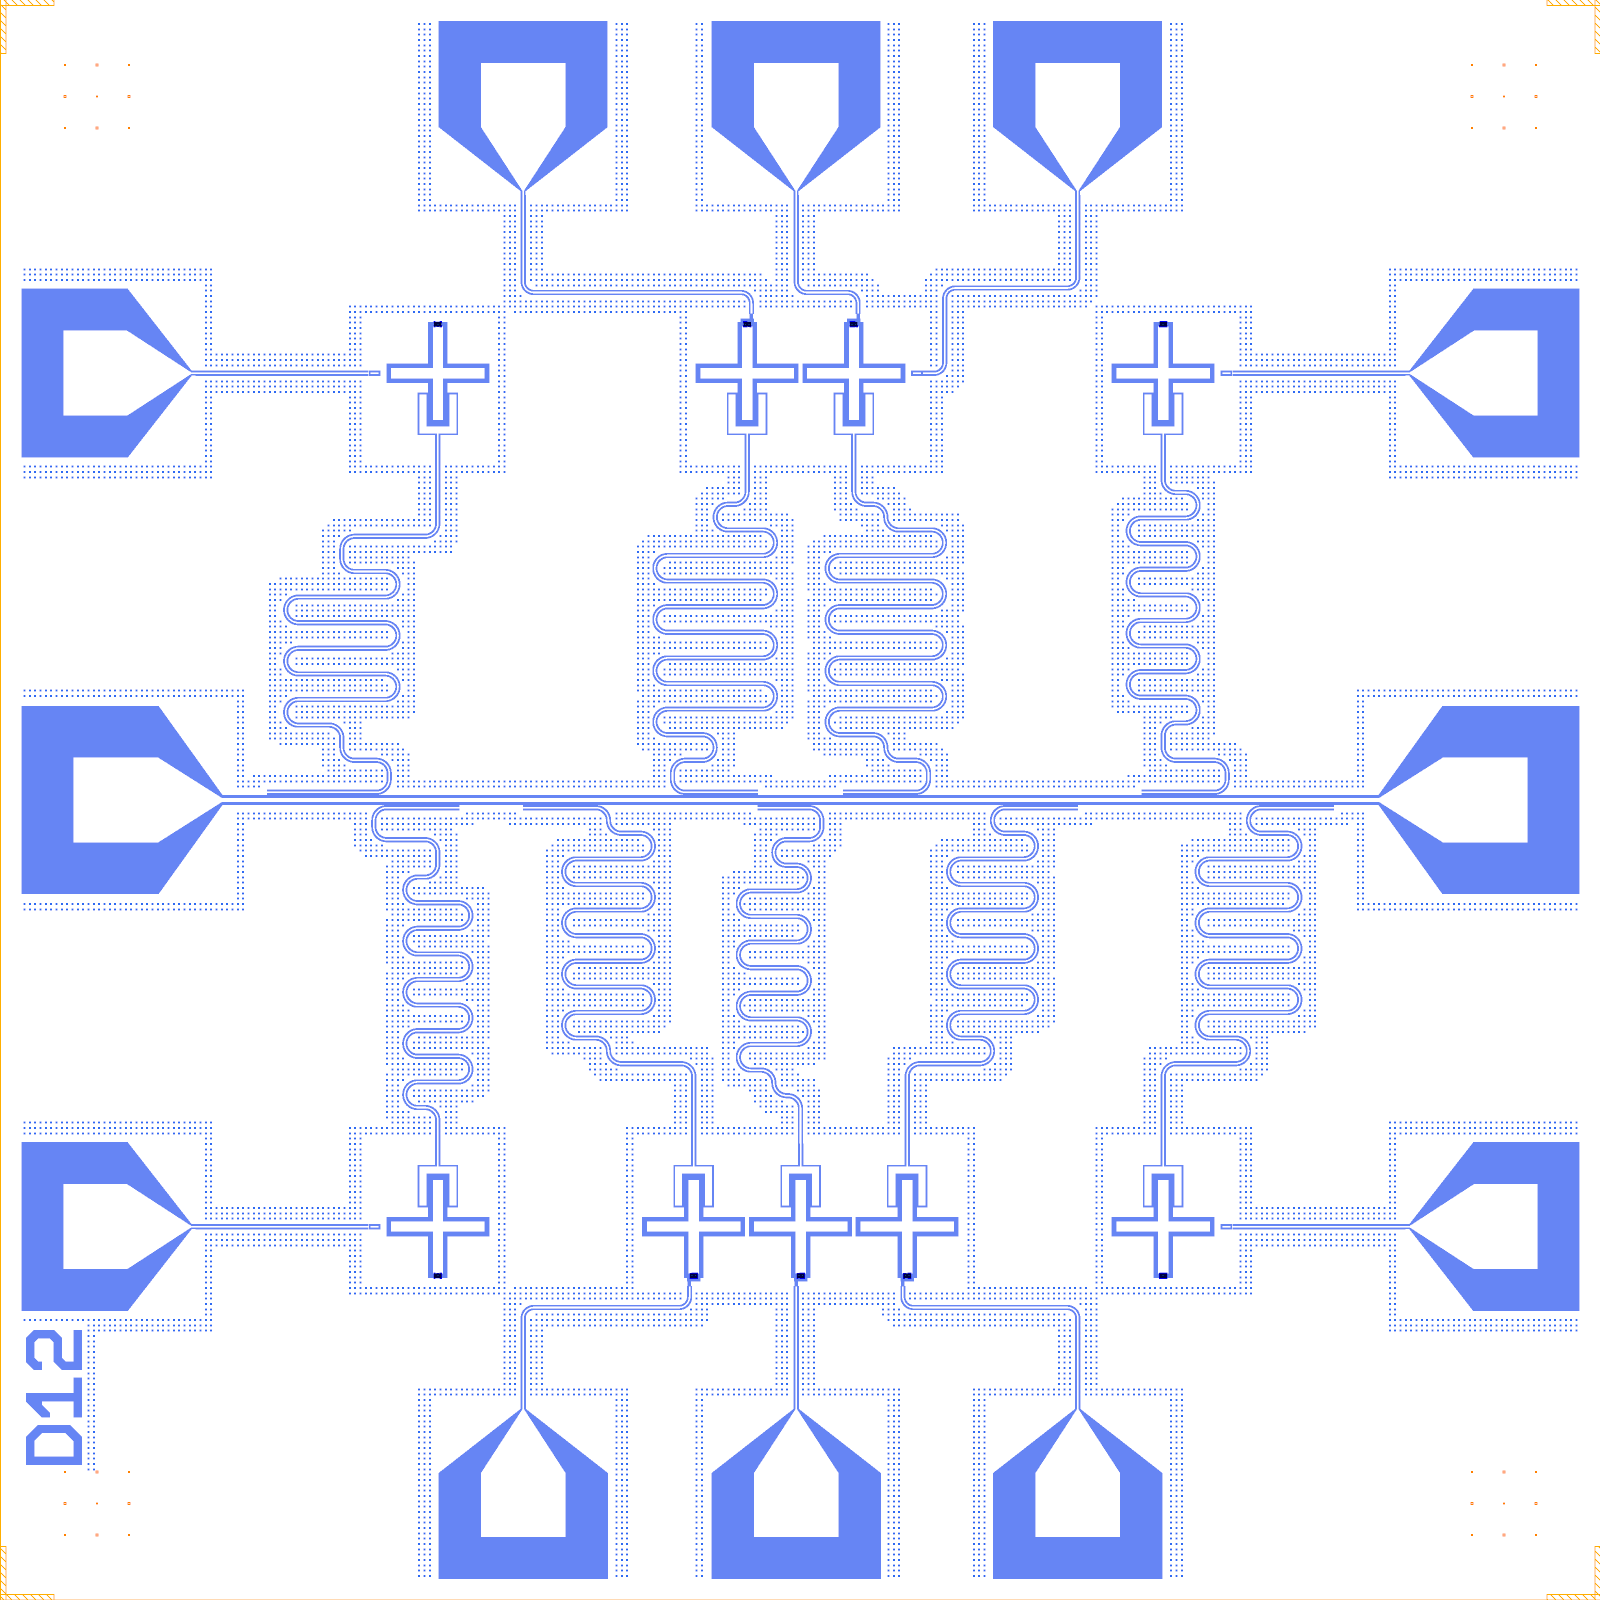

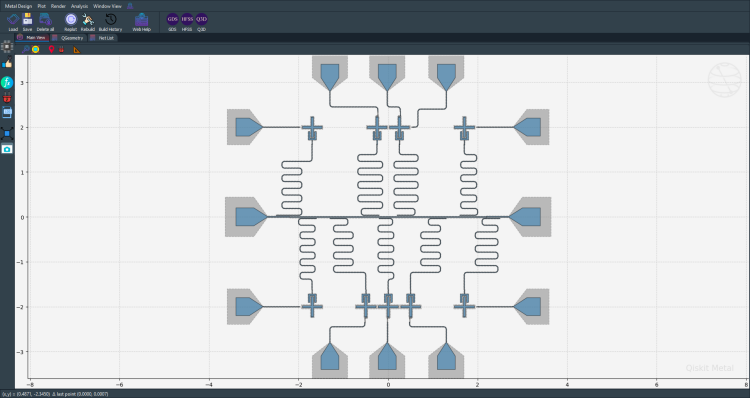

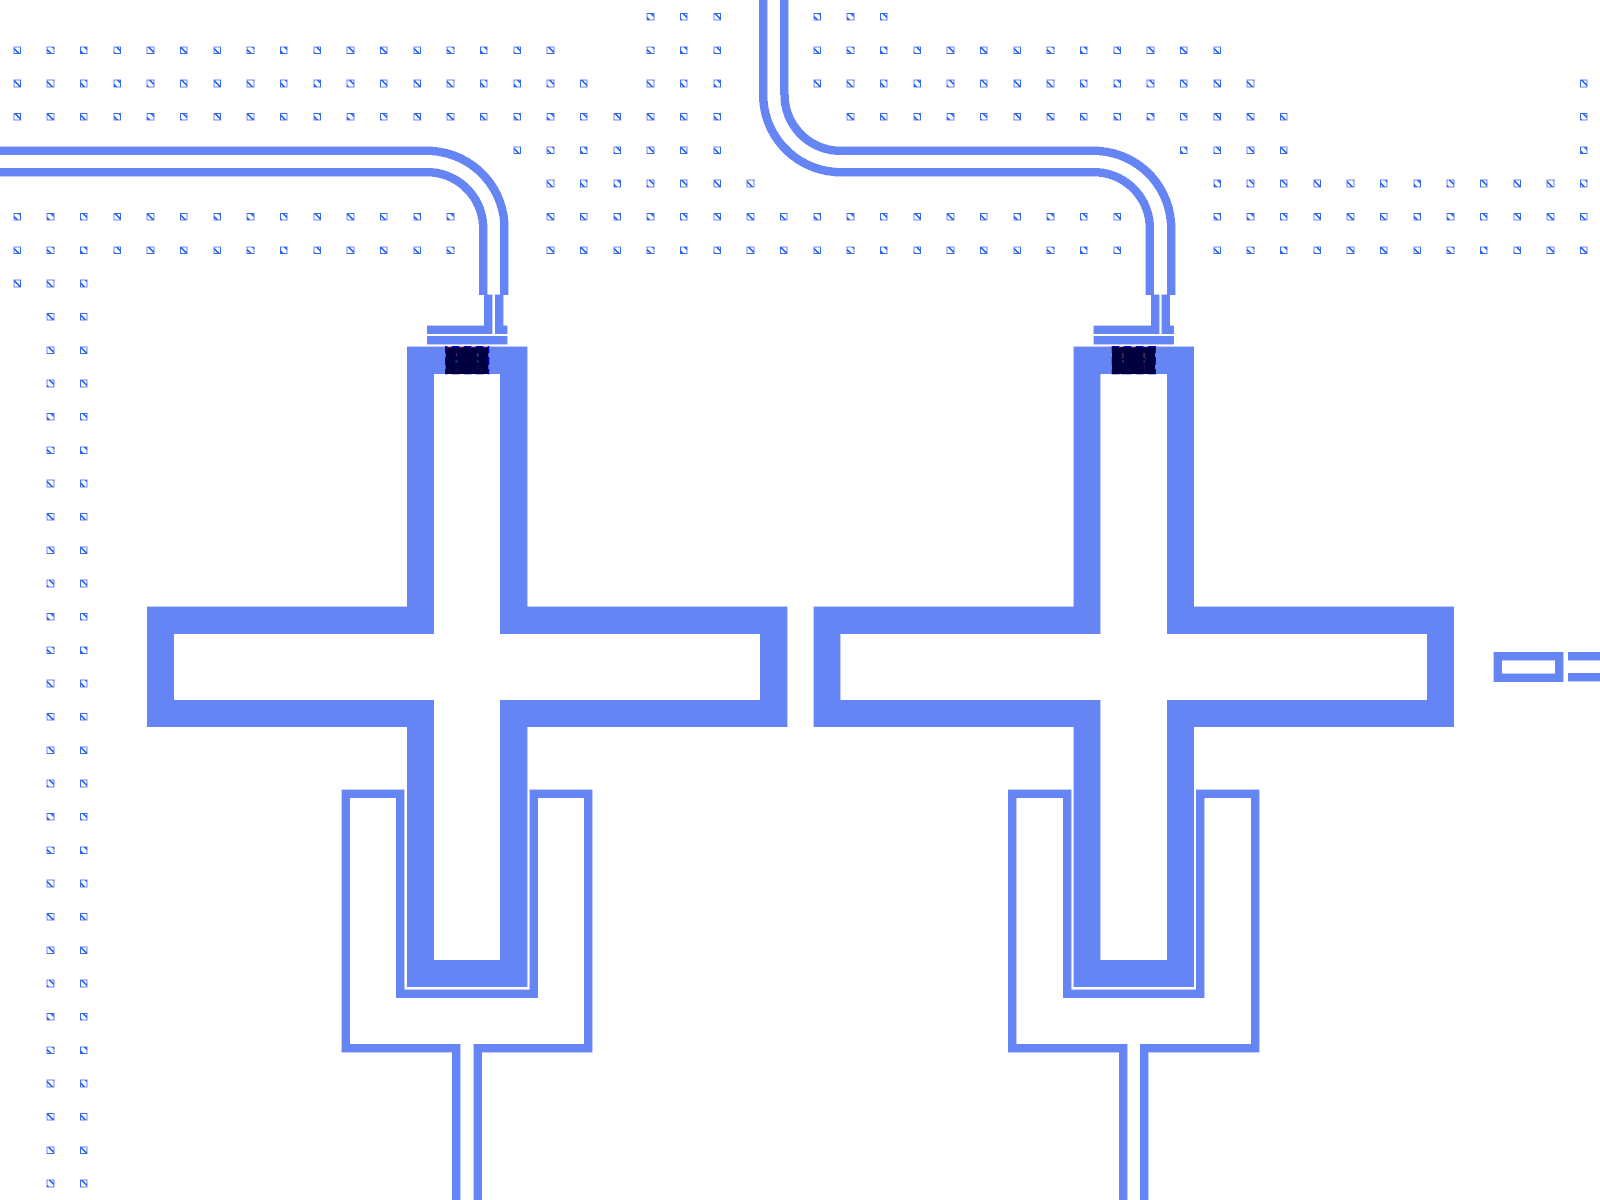

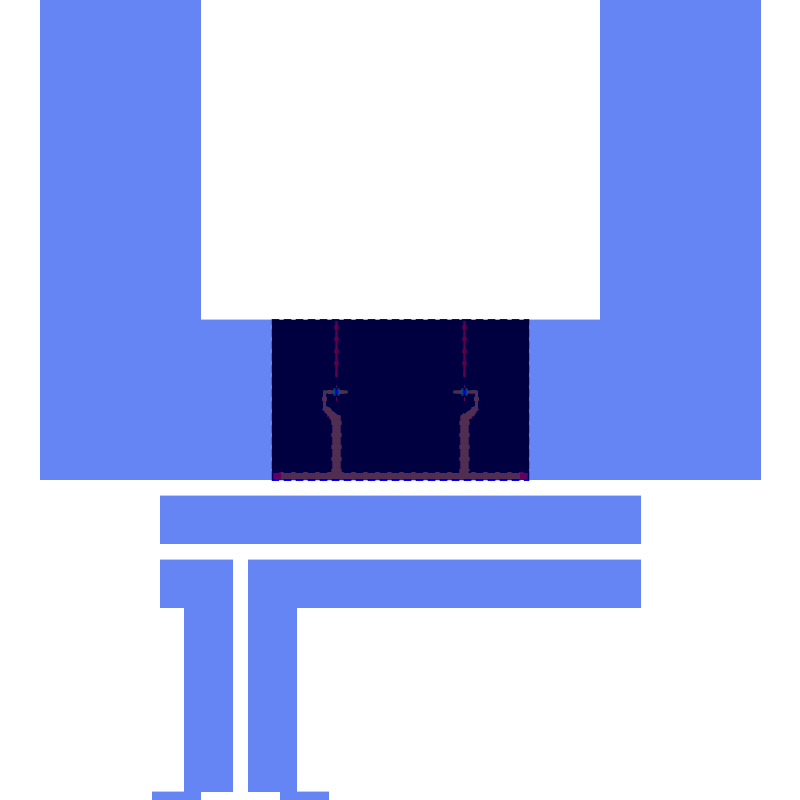

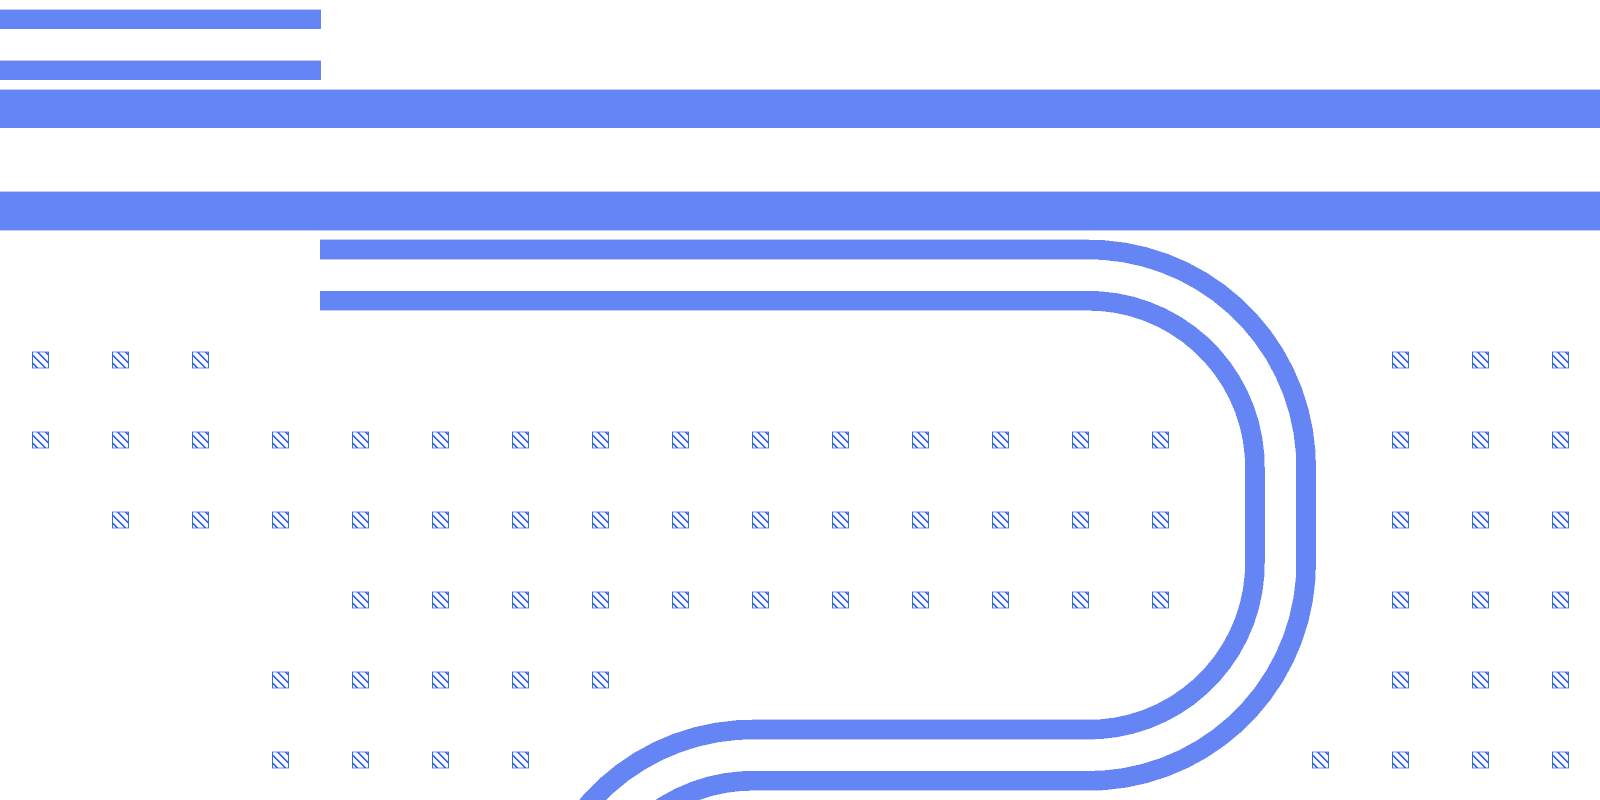

WindowsPath('examples/designs/legacy/d12_coupled_chip_coupler.png')

In [17]:
C.show_snapshot(d, OUT / f"{ID}.png", box=(0, 0, 7500, 7500), size=(1600, 1600))
display(Image(filename=str(Path("docs/images/designs/legacy") / f"{ID}_legacy.png"), width=640))   # the legacy screenshot
C.show_snapshot(d, OUT / f"{ID}_qubits.png", box=(3150, 5350, 4350, 6250), size=(1600, 1200), width=640)  # Q1–Q2
C.show_snapshot(d, OUT / f"{ID}_junction.png", box=(3700, 1470, 3800, 1570), size=(800, 800), width=320)  # Q8 SQUID
C.show_snapshot(d, OUT / f"{ID}_coupler.png", box=(3450, 3550, 3950, 3800), size=(1600, 800), width=640)  # R8 short

In [18]:
ref = LB.d12_metal_reference()
rows = ["| pin | legacy (x, y) µm | rebuilt (x, y) µm | Δ (µm) |", "|---|---|---|---|"]
for key, (x, y, _) in sorted(ref["pins"].items()):
    inst, pin = key.split(".")
    if inst not in d.data["instances"] or pin not in d[inst].ports:
        continue
    bx, by = C.port_xy(d, key)
    bx, by = bx - SHIFT[0], by - SHIFT[1]
    delta = ((bx - X0 - x) ** 2 + (by - Y0 - y) ** 2) ** 0.5
    note = (" (pad rule)" if inst in moved else "") + (" (lead 20 µm)" if inst in ("P1_C", "P2_C") and pin == "tie" else "")
    rows.append(f"| `{key}` | ({x:.1f}, {y:.1f}) | ({bx - X0:.1f}, {by - Y0:.1f}) | {delta:.2f}{note} |")
display(Markdown("\n".join(rows)))
legacy_ext = {}
for n, r in ref["routes"].items():
    if n in LB.D12_RES:
        xs, ys = [p[0] for p in r["pts"]], [p[1] for p in r["pts"]]
        legacy_ext[n] = tuple(round(v / 1000, 3) for v in (min(xs), max(xs), min(ys), max(ys)))
built = LB.route_extents(d, legacy_ext, origin=(X0 + SHIFT[0], Y0 + SHIFT[1]), shrink=11)
display(Markdown(LB.extents_md(built, legacy_ext)))

| pin | legacy (x, y) µm | rebuilt (x, y) µm | Δ (µm) |
|---|---|---|---|
| `LP_LR_00.in` | (-3595.0, -2000.0) | (-3650.0, -2000.0) | 55.00 (pad rule) |
| `LP_LR_00.tie` | (-2780.0, -2000.0) | (-2835.0, -2000.0) | 55.00 (pad rule) |
| `LP_LR_01.in` | (3595.0, -2000.0) | (3650.0, -2000.0) | 55.00 (pad rule) |
| `LP_LR_01.tie` | (2780.0, -2000.0) | (2835.0, -2000.0) | 55.00 (pad rule) |
| `LP_LR_10.in` | (-3595.0, 2000.0) | (-3650.0, 2000.0) | 55.00 (pad rule) |
| `LP_LR_10.tie` | (-2780.0, 2000.0) | (-2835.0, 2000.0) | 55.00 (pad rule) |
| `LP_LR_11.in` | (3595.0, 2000.0) | (3650.0, 2000.0) | 55.00 (pad rule) |
| `LP_LR_11.tie` | (2780.0, 2000.0) | (2835.0, 2000.0) | 55.00 (pad rule) |
| `LP_TB_00.in` | (-1300.0, -3595.0) | (-1300.0, -3650.0) | 55.00 (pad rule) |
| `LP_TB_00.tie` | (-1300.0, -2780.0) | (-1300.0, -2835.0) | 55.00 (pad rule) |
| `LP_TB_01.in` | (-20.0, -3595.0) | (-20.0, -3650.0) | 55.00 (pad rule) |
| `LP_TB_01.tie` | (-20.0, -2780.0) | (-20.0, -2835.0) | 55.00 (pad rule) |
| `LP_TB_02.in` | (1300.0, -3595.0) | (1300.0, -3650.0) | 55.00 (pad rule) |
| `LP_TB_02.tie` | (1300.0, -2780.0) | (1300.0, -2835.0) | 55.00 (pad rule) |
| `LP_TB_10.in` | (-1300.0, 3595.0) | (-1300.0, 3650.0) | 55.00 (pad rule) |
| `LP_TB_10.tie` | (-1300.0, 2780.0) | (-1300.0, 2835.0) | 55.00 (pad rule) |
| `LP_TB_11.in` | (-20.0, 3595.0) | (-20.0, 3650.0) | 55.00 (pad rule) |
| `LP_TB_11.tie` | (-20.0, 2780.0) | (-20.0, 2835.0) | 55.00 (pad rule) |
| `LP_TB_12.in` | (1300.0, 3595.0) | (1300.0, 3650.0) | 55.00 (pad rule) |
| `LP_TB_12.tie` | (1300.0, 2780.0) | (1300.0, 2835.0) | 55.00 (pad rule) |
| `P1_C.in` | (3640.0, 0.0) | (3650.0, 0.0) | 10.00 (pad rule) |
| `P1_C.tie` | (2200.0, 0.0) | (2690.0, 0.0) | 490.00 (pad rule) (lead 20 µm) |
| `P2_C.in` | (-3640.0, 0.0) | (-3650.0, 0.0) | 10.00 (pad rule) |
| `P2_C.tie` | (-2200.0, 0.0) | (-2690.0, 0.0) | 490.00 (pad rule) (lead 20 µm) |
| `Q0.a` | (-1700.0, 1617.0) | (-1700.0, 1617.0) | 0.00 |
| `Q0.bus_drive` | (-2026.0, 2000.0) | (-2026.0, 2000.0) | 0.00 |
| `Q1.a` | (-250.0, 1617.0) | (-250.0, 1617.0) | 0.00 |
| `Q1.flux_line` | (-230.0, 2279.0) | (-230.0, 2279.0) | 0.00 |
| `Q2.a` | (250.0, 1617.0) | (250.0, 1617.0) | 0.00 |
| `Q2.bus_drive` | (576.0, 2000.0) | (576.0, 2000.0) | 0.00 |
| `Q2.flux_line` | (270.0, 2279.0) | (270.0, 2279.0) | 0.00 |
| `Q3.a` | (1700.0, 1617.0) | (1700.0, 1617.0) | 0.00 |
| `Q3.bus_drive` | (2026.0, 2000.0) | (2026.0, 2000.0) | 0.00 |
| `Q4.a` | (-1700.0, -1617.0) | (-1700.0, -1617.0) | 0.00 |
| `Q4.bus_drive` | (-2026.0, -2000.0) | (-2026.0, -2000.0) | 0.00 |
| `Q5.a` | (-500.0, -1617.0) | (-500.0, -1617.0) | 0.00 |
| `Q5.flux_line` | (-520.0, -2279.0) | (-520.0, -2279.0) | 0.00 |
| `Q6.a` | (500.0, -1617.0) | (500.0, -1617.0) | 0.00 |
| `Q6.flux_line` | (480.0, -2279.0) | (480.0, -2279.0) | 0.00 |
| `Q7.a` | (1700.0, -1617.0) | (1700.0, -1617.0) | 0.00 |
| `Q7.bus_drive` | (2026.0, -2000.0) | (2026.0, -2000.0) | 0.00 |
| `Q8.a` | (0.0, -1617.0) | (0.0, -1617.0) | 0.00 |
| `Q8.flux_line` | (-20.0, -2279.0) | (-20.0, -2279.0) | 0.00 |

| route | legacy x (mm) | rebuilt x (mm) | legacy y (mm) | rebuilt y (mm) | max abs Δ (µm) |
|---|---|---|---|---|---|
| R0 | [-2.500, -1.700] | [-2.489, -1.700] | [0.036, 1.617] | [0.036, 1.606] | 11 |
| R1 | [-0.676, -0.124] | [-0.683, -0.117] | [0.036, 1.617] | [0.036, 1.606] | 11 |
| R2 | [0.131, 0.669] | [0.125, 0.675] | [0.036, 1.617] | [0.036, 1.606] | 11 |
| R3 | [1.600, 2.000] | [1.536, 2.000] | [0.036, 1.617] | [0.036, 1.606] | 64 |
| R4 | [-2.000, -1.600] | [-2.000, -1.545] | [-1.617, -0.036] | [-1.606, -0.036] | 55 |
| R5 | [-1.300, -0.500] | [-1.289, -0.500] | [-1.617, -0.036] | [-1.606, -0.036] | 11 |
| R6 | [0.500, 1.300] | [0.500, 1.289] | [-1.617, -0.036] | [-1.606, -0.036] | 11 |
| R7 | [1.700, 2.500] | [1.700, 2.489] | [-1.617, -0.036] | [-1.606, -0.036] | 11 |
| R8 | [-0.226, 0.126] | [-0.291, 0.100] | [-1.617, -0.036] | [-1.606, -0.036] | 65 |

## 16 · Summary

- **Matches the source:** every qubit pin at its legacy position (Δ 0.00 µm against the headless Metal rebuild);
  the readout extents within 11 µm (R3, R4, R8 within 55–65 µm: the KQC meander on one segment); the nine lengths,
  the couplers and shorts.
- **Differs, by the PDK:** the twelve launchpads at `pad_edge` = 100 µm (feed pads 10 µm out, line pads 55 µm out:
  `cpw_main` 5360 → 5380 µm, each flux / drive line 55 µm longer; the hangers pinned, so the couplers did not move);
  the PDK junction cells at 45 kΩ; the PDK frame and device ID `D12` (left edge); the PDK cheese band (fab cheese
  source "build", 14723 holes). Centring shift (0, 0).
- **Open:** Q0/R0 hybridised (R_n 40 kΩ would move Q0 to 5.32 GHz, χ 65 → −7.4 MHz, step 13), Q7/R7 close; the arm
  couplings are estimates until the FEM groups are solved; no PDK design warnings.